In [ ]:
EXPERIMENT 8: DATA CLEANING AND EDA


Saving experiment_8_student_performance - experiment_8_student_performance.csv to experiment_8_student_performance - experiment_8_student_performance (1).csv

===== ORIGINAL DATASET =====
  Student_ID   Name Department  Attendance_Percentage  Assignment_Score  \
0       S101  Aarav        CSE                   92.0              88.0   
1       S102   Diya        ECE                   85.0              76.0   
2       S103  Kavin        CSE                   78.0              81.0   
3       S104  Meera         IT                   96.0              93.0   
4       S105  Arjun        ECE                    NaN              72.0   

   Exam_Score  
0        91.0  
1        82.0  
2        79.0  
3        95.0  
4        75.0  

Dataset Shape: (22, 6)

===== MISSING VALUES =====
Student_ID               0
Name                     0
Department               1
Attendance_Percentage    3
Assignment_Score         1
Exam_Score               1
dtype: int64

Duplicate Records: 1

===== CLEANED D

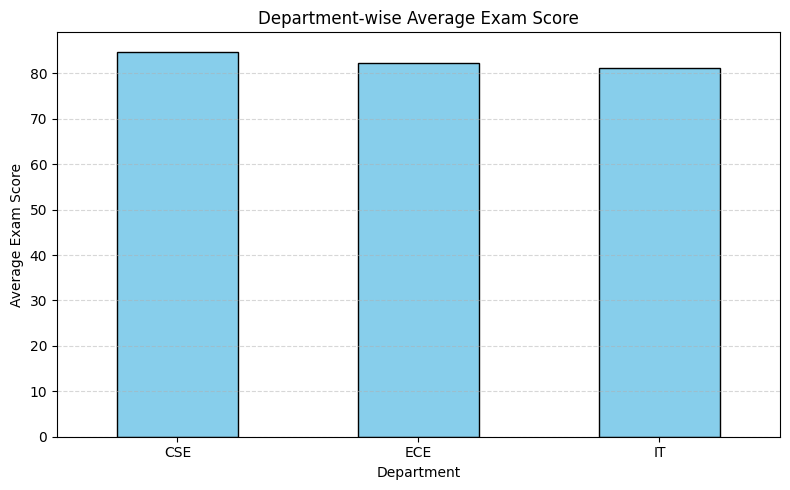

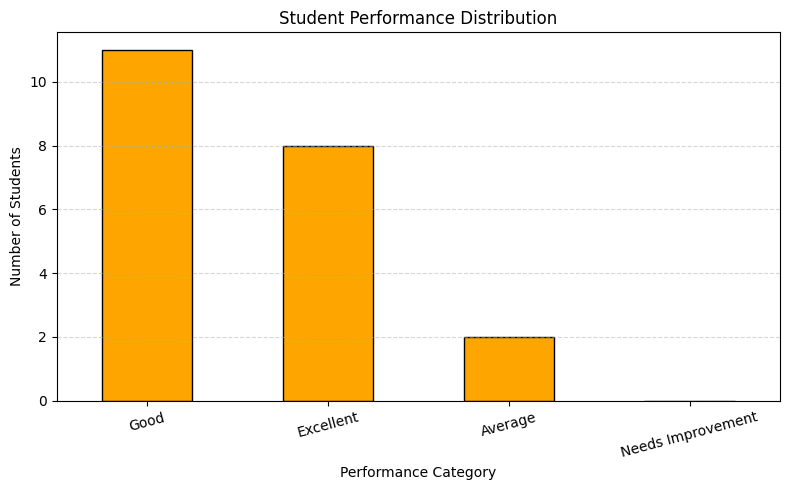


Data Cleaning and EDA Completed Successfully!


In [ ]:
# Experiment 8: Data Cleaning and EDA
# Using Pandas and Matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload CSV file
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("\n===== ORIGINAL DATASET =====")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# Handle missing numerical values
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Calculate average score
df["Average_Score"] = df[
    ["Assignment_Score", "Exam_Score"]
].mean(axis=1)

# Classify student performance
df["Performance"] = pd.cut(
    df["Average_Score"],
    bins=[-1, 50, 70, 85, 100],
    labels=[
        "Needs Improvement",
        "Average",
        "Good",
        "Excellent"
    ]
)

print("\n===== CLEANED DATASET =====")
print(df.head(10))

print("\nCleaned Dataset Shape:", df.shape)

# Statistical analysis
print("\n===== STATISTICAL SUMMARY =====")
print(df.describe().round(2))

# Department-wise analysis
dept_analysis = df.groupby(
    "Department"
)["Exam_Score"].mean()

print("\n===== DEPARTMENT-WISE AVERAGE =====")
print(dept_analysis.round(2))

# Performance distribution
print("\n===== PERFORMANCE DISTRIBUTION =====")
print(df["Performance"].value_counts())

# Visualization 1: Department-wise average score
plt.figure(figsize=(8, 5))

dept_analysis.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Department-wise Average Exam Score")
plt.xlabel("Department")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Visualization 2: Student performance distribution
plt.figure(figsize=(8, 5))

df["Performance"].value_counts().plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("\nData Cleaning and EDA Completed Successfully!")